In [64]:

# Import libraries for checking public webpage access
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time
from pathlib import Path

print("All required libraries imported successfully!")


All required libraries imported successfully!


In [65]:
%pip install requests beautifulsoup4 pandas

Note: you may need to restart the kernel to use updated packages.


In [66]:

# Check the product page without bypassing website restrictions

product_url = (
    "https://www.bestbuy.ca/en-ca/product/"
    "refurbished-excellent-apple-iphone-14-128gb-midnight-unlocked/16553704"
)

try:
    response = requests.get(product_url, timeout=20)

    print("HTTP status code:", response.status_code)
    print("Page accessible:", response.ok)

    if response.ok:
        soup = BeautifulSoup(response.text, "html.parser")
        print("Page title:", soup.title.get_text(strip=True) if soup.title else "Not found")
        print("HTML downloaded:", len(response.text), "characters")
    else:
        print("The page did not allow this request.")
        print("Do not attempt to bypass access restrictions.")

except requests.RequestException as error:
    print("Request failed:", error)


Request failed: HTTPSConnectionPool(host='www.bestbuy.ca', port=443): Read timed out. (read timeout=20)


In [67]:

# Check whether review-related text exists in the HTML.
# This uses a normal request and does not bypass access controls.

if "response" in globals() and response.ok:
    page_text = response.text.lower()

    keywords = ["customer reviews", "review", "rating", "show more"]

    print("Page title:", soup.title.get_text(strip=True) if soup.title else "Not found")

    for word in keywords:
        print(f"'{word}' found in HTML:", word in page_text)

else:
    print("No successful HTML response is available.")
    print("The earlier request was reset, so we cannot inspect its HTML.")


No successful HTML response is available.
The earlier request was reset, so we cannot inspect its HTML.


In [68]:

# Step 5: Prepare to load an authorized review dataset

from pathlib import Path
import pandas as pd

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

print("Data folder ready:", DATA_DIR.resolve())
print("Place your authorized review CSV file in this folder.")


Data folder ready: C:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\data
Place your authorized review CSV file in this folder.


In [69]:

# Check for CSV files in the data folder

csv_files = list(DATA_DIR.glob("*.csv"))

if csv_files:
    print("CSV files found:")
    for file in csv_files:
        print("-", file.name)
else:
    print("No CSV files found yet.")
    print("Add an authorized review CSV file to the data folder.")


No CSV files found yet.
Add an authorized review CSV file to the data folder.


In [70]:

from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id="IberaSoft/ecommerce-reviews-sentiment",
    repo_type="dataset"
)

print("Files available in the dataset repository:")
for file in files:
    print(file)


ModuleNotFoundError: No module named 'huggingface_hub'

In [ ]:
%pip install huggingface_hub

In [ ]:
from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id="IberaSoft/ecommerce-reviews-sentiment",
    repo_type="dataset"
)

print("Files available in the dataset repository:")
for file in files:
    print(file)

In [1]:
print("Notebook is working!")

Notebook is working!


In [2]:
%pip install huggingface_hub

  Using cached truststore-0.10.5-py3-none-any.whl.metadata (4.5 kB)
   ---------------------------------------- 0.0/855.2 kB ? eta -:--:--
   ------------ --------------------------- 262.1/855.2 kB ? eta -:--:--
   ------------------------------------ --- 786.4/855.2 kB 2.4 MB/s eta 0:00:01
   ---------------------------------------- 855.2/855.2 kB 2.1 MB/s  0:00:00
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   -- ------------------------------------- 0.3/3.8 MB ? eta -:--:--
   -------- ------------------------------- 0.8/3.8 MB 2.4 MB/s eta 0:00:02
   ------------- -------------------------- 1.3/3.8 MB 2.6 MB/s eta 0:00:01
   --------------------- ------------------ 2.1/3.8 MB 2.6 MB/s eta 0:00:01
   --------------------------- ------------ 2.6/3.8 MB 2.7 MB/s eta 0:00:01
   ----------------------------------- ---- 3.4/3.8 MB 2.8 MB/s eta 0:00:01
   ---------------------------------------- 3.8/3.8 MB 2.8 MB/s  0:00:01
Using cached truststore-0.10.5-py3-none-

In [3]:
from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id="IberaSoft/ecommerce-reviews-sentiment",
    repo_type="dataset"
)

print("Files available:")
print(files)

Files available:
['.gitattributes', 'README.md']


In [4]:
from pathlib import Path

project_folder = Path.cwd()

print("Project folder:", project_folder)
print("\nCSV and Excel files found:")

for file in project_folder.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".csv", ".xlsx", ".xls"]:
        if ".venv" not in str(file):
            print(file)

Project folder: c:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis

CSV and Excel files found:
c:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\outputs\product_reviews_sentiment.csv
c:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\outputs\product_reviews_sentiment.xlsx


In [5]:
import pandas as pd
from pathlib import Path

csv_path = Path("outputs/product_reviews_sentiment.csv")

df = pd.read_csv(csv_path)

print("Number of reviews:", len(df))
print("\nColumn names:")
print(df.columns.tolist())

print("\nReview data:")
display(df.head())

Number of reviews: 3

Column names:
['primary_key', 'title', 'review_text', 'date', 'rating', 'source', 'reviewer_name', 'sentiment', 'sentiment_score']

Review data:


,primary_key,title,review_text,date,rating,source,reviewer_name,sentiment,sentiment_score
0,TEST001,Excellent product,This product works perfectly and is very easy ...,2026-09-15,5,Illustrative test data,Test Reviewer 1,Positive,0.8122
1,TEST002,Average quality,"The product is okay, but the quality could be ...",2026-09-16,3,Illustrative test data,Test Reviewer 2,Positive,0.6486
2,TEST003,Very disappointing,It stopped working quickly and I am very unhappy.,2026-09-17,1,Illustrative test data,Test Reviewer 3,Negative,-0.6115


In [6]:
import pandas as pd
from pathlib import Path

columns = [
    "primary_key",
    "title",
    "review_text",
    "date",
    "rating",
    "source",
    "reviewer_name"
]

df = pd.DataFrame(columns=columns)

output_folder = Path("data")
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "bestbuy_reviews.csv"
df.to_csv(output_file, index=False)

print("CSV template created:", output_file.resolve())
print("Columns:", columns)

CSV template created: C:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\data\bestbuy_reviews.csv
Columns: ['primary_key', 'title', 'review_text', 'date', 'rating', 'source', 'reviewer_name']


In [7]:

import pandas as pd
from pathlib import Path

# Create the review using the details you collected
review = {
    "primary_key": "BB001",
    "title": "Truly Excellent and Worth the Price",
    "review_text": "I purchased a refurbished iPhone 14 in Excellent condition for my dad, and I’m very pleased with the experience. The phone arrived in less than six days, looking practically brand new with a smooth, flawless display and 97 percent battery health. Performance is fast and reliable, and for a refurbished unit, it feels premium right out of the box. The iPhone 14 is powerful enough to remain a solid daily driver well into 2030, depending on the user’s needs and habits. Overall, this is great value and a smart buy for anyone considering a quality device without paying full price.",
    "date": "2025-09-18",
    "rating": 5,
    "source": "Best Buy Canada",
    "reviewer_name": "Space Marcus"
}

# Save to the data folder
output_folder = Path("data")
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "bestbuy_reviews.csv"

# Append to the file if it already has reviews
if output_file.exists() and output_file.stat().st_size > 0:
    existing = pd.read_csv(output_file)
    if review["primary_key"] not in existing["primary_key"].astype(str).values:
        updated = pd.concat([existing, pd.DataFrame([review])], ignore_index=True)
        updated.to_csv(output_file, index=False)
else:
    pd.DataFrame([review]).to_csv(output_file, index=False)

print("Review saved!")
print("File:", output_file.resolve())
print("Review ID:", review["primary_key"])

display(pd.read_csv(output_file).tail())


Review saved!
File: C:\Users\Admin\Documents\HanuAI_ML_Assessment\Task_1_Sentiment_Analysis\data\bestbuy_reviews.csv
Review ID: BB001


,primary_key,title,review_text,date,rating,source,reviewer_name
0,BB001,Truly Excellent and Worth the Price,I purchased a refurbished iPhone 14 in Excelle...,2025-09-18,5,Best Buy Canada,Space Marcus


In [8]:

import pandas as pd
from pathlib import Path

output_file = Path("data/bestbuy_reviews.csv")

# Enter each new review in this list
new_reviews = [
    {
        "primary_key": "BB002",
        "title": "Enter the actual review title",
        "review_text": "Paste the actual customer review here",
        "date": "2025-09-18",
        "rating": 4,
        "source": "Best Buy Canada",
        "reviewer_name": "Enter the displayed reviewer name"
    }
]

existing = pd.read_csv(output_file)

for review in new_reviews:
    if review["primary_key"] not in existing["primary_key"].astype(str).values:
        existing = pd.concat(
            [existing, pd.DataFrame([review])],
            ignore_index=True
        )

existing.to_csv(output_file, index=False)

print("Total reviews saved:", len(existing))
display(existing.tail())


Total reviews saved: 2


,primary_key,title,review_text,date,rating,source,reviewer_name
0,BB001,Truly Excellent and Worth the Price,I purchased a refurbished iPhone 14 in Excelle...,2025-09-18,5,Best Buy Canada,Space Marcus
1,BB002,Enter the actual review title,Paste the actual customer review here,2025-09-18,4,Best Buy Canada,Enter the displayed reviewer name


In [9]:

import pandas as pd
from pathlib import Path

output_file = Path("data/bestbuy_reviews.csv")

# Enter each new review in this list
new_reviews = [
    {
        "primary_key": "BB002",
        "title": "Great phone!",
        "review_text": "Perfect phone for me for the price. Much better than paying for a new iPhone 17. I don’t need the latest and the greatest. This phone is very similar to iPhone X which I had to replace as the technology was so old. The phone arrived one week after I ordered it. All my apps ported over perfectly, but I ended up taking the phone to my service provider so they could swap out the SIM card (no charge for that). The new phone has eSIM capabilities, which the old phone didn’t. When the time comes to replace iPhone 14 I will do it through Best Buy again and buy another refurbished phone.",
        "date": "",
        "rating": 5,
        "source": "Best Buy Canada",
        "reviewer_name": "Reviewed by Bunny"
    }
]

existing = pd.read_csv(output_file)

for review in new_reviews:
    if review["primary_key"] not in existing["primary_key"].astype(str).values:
        existing = pd.concat(
            [existing, pd.DataFrame([review])],
            ignore_index=True
        )

existing.to_csv(output_file, index=False)

print("Total reviews saved:", len(existing))
display(existing.tail())


Total reviews saved: 2


,primary_key,title,review_text,date,rating,source,reviewer_name
0,BB001,Truly Excellent and Worth the Price,I purchased a refurbished iPhone 14 in Excelle...,2025-09-18,5,Best Buy Canada,Space Marcus
1,BB002,Enter the actual review title,Paste the actual customer review here,2025-09-18,4,Best Buy Canada,Enter the displayed reviewer name


In [10]:

import pandas as pd
from pathlib import Path

output_file = Path("data/bestbuy_reviews.csv")

# Enter each new review in this list
new_reviews = [
    {
        "primary_key": "BB003",
        "title": "Great functionality wise and cosmetically",
        "review_text": "received the phone extremely fast, came in generic packaging. It was a box stuffed in a Telus bag which was sent in a purolator box. I’d suggest maybe better packaging in the event of rough handling to ensure the package/ product doesn’t get damaged. the phone itself was in excellent condition as advertised with an 87% battery life- was hoping for at least 90% but it’s understandable if you’re buying a refurbished phone. there were no scratches or marks on the phone, and the phone functionality is perfect. the phone was unlocked and ready to set up immediately, inside the packaging also came with a small charger. i’ve only had the phone for a few days now but it seems to be functioning perfectly. i bought this phone from Mastercom, i was a bit hesitant wanting to purchase from this seller having seen their reviews. however, the phone is in excellent condition and it’s working very well so far.",
        "date": " February 12, 2025",
        "rating": 5,
        "source": "Reviewed by Mar",
        "reviewer_name": "Enter the displayed reviewer name"
    }
]

existing = pd.read_csv(output_file)

for review in new_reviews:
    if review["primary_key"] not in existing["primary_key"].astype(str).values:
        existing = pd.concat(
            [existing, pd.DataFrame([review])],
            ignore_index=True
        )

existing.to_csv(output_file, index=False)

print("Total reviews saved:", len(existing))
display(existing.tail())


Total reviews saved: 3


,primary_key,title,review_text,date,rating,source,reviewer_name
0,BB001,Truly Excellent and Worth the Price,I purchased a refurbished iPhone 14 in Excelle...,2025-09-18,5,Best Buy Canada,Space Marcus
1,BB002,Enter the actual review title,Paste the actual customer review here,2025-09-18,4,Best Buy Canada,Enter the displayed reviewer name
2,BB003,Great functionality wise and cosmetically,"received the phone extremely fast, came in gen...","February 12, 2025",5,Reviewed by Mar,Enter the displayed reviewer name


In [11]:
import pandas as pd
from pathlib import Path

output_file = Path("data/bestbuy_reviews.csv")

# Enter each new review in this list
new_reviews = [
    {
        "primary_key": "BB002",
        "title": "Great phone",
        "review_text": "received the phone extremely fast, came in generic packaging. It was a box stuffed in a Telus bag which was sent in a purolator box. I’d suggest maybe better packaging in the event of rough handling to ensure the package/ product doesn’t get damaged. the phone itself was in excellent condition as advertised with an 87% battery life- was hoping for at least 90% but it’s understandable if you’re buying a refurbished phone. there were no scratches or marks on the phone, and the phone functionality is perfect. the phone was unlocked and ready to set up immediately, inside the packaging also came with a small charger. i’ve only had the phone for a few days now but it seems to be functioning perfectly. i bought this phone from Mastercom, i was a bit hesitant wanting to purchase from this seller having seen their reviews. however, the phone is in excellent condition and it’s working very well so far.",
        "date": " October 22, 2025",
        "rating": 5,
        "source": "Canada",
        "reviewer_name": "Reviewed by Bunny"
    }
]

existing = pd.read_csv(output_file)

for review in new_reviews:
    if review["primary_key"] not in existing["primary_key"].astype(str).values:
        existing = pd.concat(
            [existing, pd.DataFrame([review])],
            ignore_index=True
        )

existing.to_csv(output_file, index=False)

print("Total reviews saved:", len(existing))
display(existing.tail())


Total reviews saved: 3


,primary_key,title,review_text,date,rating,source,reviewer_name
0,BB001,Truly Excellent and Worth the Price,I purchased a refurbished iPhone 14 in Excelle...,2025-09-18,5,Best Buy Canada,Space Marcus
1,BB002,Enter the actual review title,Paste the actual customer review here,2025-09-18,4,Best Buy Canada,Enter the displayed reviewer name
2,BB003,Great functionality wise and cosmetically,"received the phone extremely fast, came in gen...","February 12, 2025",5,Reviewed by Mar,Enter the displayed reviewer name


In [12]:
import pandas as pd
from pathlib import Path

file_path = Path("data/bestbuy_reviews.csv")
df = pd.read_csv(file_path)

print("Total reviews:", len(df))
print("\nMissing values:")
print(df.isnull().sum())

print("\nSaved reviews:")
display(df[["primary_key", "title", "date", "rating", "reviewer_name"]])

Total reviews: 3

Missing values:
primary_key      0
title            0
review_text      0
date             0
rating           0
source           0
reviewer_name    0
dtype: int64

Saved reviews:


,primary_key,title,date,rating,reviewer_name
0,BB001,Truly Excellent and Worth the Price,2025-09-18,5,Space Marcus
1,BB002,Enter the actual review title,2025-09-18,4,Enter the displayed reviewer name
2,BB003,Great functionality wise and cosmetically,"February 12, 2025",5,Enter the displayed reviewer name


In [13]:
import pandas as pd
from pathlib import Path

file_path = Path("data/bestbuy_reviews.csv")
df = pd.read_csv(file_path)

# Convert dates to YYYY-MM-DD format
df["date"] = pd.to_datetime(
    df["date"], errors="coerce"
).dt.strftime("%Y-%m-%d")

# Save the corrected date format
df.to_csv(file_path, index=False)

print("Dates formatted successfully.")
display(df[["primary_key", "title", "date", "rating", "reviewer_name"]])

Dates formatted successfully.


,primary_key,title,date,rating,reviewer_name
0,BB001,Truly Excellent and Worth the Price,2025-09-18,5,Space Marcus
1,BB002,Enter the actual review title,2025-09-18,4,Enter the displayed reviewer name
2,BB003,Great functionality wise and cosmetically,NaN,5,Enter the displayed reviewer name


In [ ]:
import pandas as pd
from pathlib import Path

file_path = Path("data/bestbuy_reviews.csv")
df = pd.read_csv(file_path)

# Convert dates to YYYY-MM-DD format
df["date"] = pd.to_datetime(
    df["date"], errors="coerce"
).dt.strftime("October 22, 2025")

# Save the corrected date format
df.to_csv(file_path, index=False)

print("Dates formatted successfully.")
display(df[["primary_key", "title", "date", "rating", "reviewer_name"]])

In [ ]:

import pandas as pd
from pathlib import Path

file_path = Path("data/bestbuy_reviews.csv")
df = pd.read_csv(file_path)

# Replace these example values with the REAL details from Best Buy
df.loc[df["primary_key"] == "BB002", "title"] = "Great phone!"
df.loc[df["primary_key"] == "BB002", "reviewer_name"] = "Reviewed by Bunny"
df.loc[df["primary_key"] == "BB002", "review_text"] = "Perfect phone for me for the price. Much better than paying for a new iPhone 17. I don’t need the latest and the greatest. This phone is very similar to iPhone X which I had to replace as the technology was so old. The phone arrived one week after I ordered it. All my apps ported over perfectly, but I ended up taking the phone to my service provider so they could swap out the SIM card (no charge for that). The new phone has eSIM capabilities, which the old phone didn’t. When the time comes to replace iPhone 14 I will do it through Best Buy again and buy another refurbished phone."

df.loc[df["primary_key"] == "BB003", "reviewer_name"] = "Reviewed by Mar"
df.loc[df["primary_key"] == "BB003", "review_text"] = "received the phone extremely fast, came in generic packaging. It was a box stuffed in a Telus bag which was sent in a purolator box. I’d suggest maybe better packaging in the event of rough handling to ensure the package/ product doesn’t get damaged. the phone itself was in excellent condition as advertised with an 87% battery life- was hoping for at least 90% but it’s understandable if you’re buying a refurbished phone. there were no scratches or marks on the phone, and the phone functionality is perfect. the phone was unlocked and ready to set up immediately, inside the packaging also came with a small charger. i’ve only had the phone for a few days now but it seems to be functioning perfectly. i bought this phone from Mastercom, i was a bit hesitant wanting to purchase from this seller having seen their reviews. however, the phone is in excellent condition and it’s working very well so far"

# Correct the BB003 date only if February 12, 2025 is the date shown
df.loc[df["primary_key"] == "BB003", "date"] = "February 12, 2025"

df.to_csv(file_path, index=False)

print("Review file updated.")
display(df[["primary_key", "title", "date", "rating", "reviewer_name"]])


SyntaxError: unterminated string literal (detected at line 13) (4231711016.py, line 13)

In [15]:
import pandas as pd
from pathlib import Path

file_path = Path("data/bestbuy_reviews.csv")
df = pd.read_csv(file_path)

# Replace these example values with the REAL details from Best Buy
df.loc[df["primary_key"] == "BB002", "title"] = "Great phone!"
df.loc[df["primary_key"] == "BB002", "reviewer_name"] = "Reviewed by Bunny"
df.loc[df["primary_key"] == "BB002", "review_text"] = "Perfect phone for me for the price. Much better than paying for a new iPhone 17. I don’t need the latest and the greatest. This phone is very similar to iPhone X which I had to replace as the technology was so old. The phone arrived one week after I ordered it. All my apps ported over perfectly, but I ended up taking the phone to my service provider so they could swap out the SIM card (no charge for that). The new phone has eSIM capabilities, which the old phone didn’t. When the time comes to replace iPhone 14 I will do it through Best Buy again and buy another refurbished phone."

df.loc[df["primary_key"] == "BB003", "reviewer_name"] = "Reviewed by Mar"
df.loc[df["primary_key"] == "BB003", "review_text"] = "received the phone extremely fast, came in generic packaging. It was a box stuffed in a Telus bag which was sent in a purolator box. I’d suggest maybe better packaging in the event of rough handling to ensure the package/ product doesn’t get damaged. the phone itself was in excellent condition as advertised with an 87% battery life- was hoping for at least 90% but it’s understandable if you’re buying a refurbished phone. there were no scratches or marks on the phone, and the phone functionality is perfect. the phone was unlocked and ready to set up immediately, inside the packaging also came with a small charger. i’ve only had the phone for a few days now but it seems to be functioning perfectly. i bought this phone from Mastercom, i was a bit hesitant wanting to purchase from this seller having seen their reviews. however, the phone is in excellent condition and it’s working very well so far"

# Correct the BB003 date only if February 12, 2025 is the date shown
df.loc[df["primary_key"] == "BB003", "date"] = "February 12, 2025"

df.to_csv(file_path, index=False)

print("Review file updated.")
display(df[["primary_key", "title", "date", "rating", "reviewer_name"]])


Review file updated.


,primary_key,title,date,rating,reviewer_name
0,BB001,Truly Excellent and Worth the Price,2025-09-18,5,Space Marcus
1,BB002,Great phone!,2025-09-18,4,Reviewed by Bunny
2,BB003,Great functionality wise and cosmetically,"February 12, 2025",5,Reviewed by Mar


In [16]:

import pandas as pd
from pathlib import Path

file_path = Path("data/bestbuy_reviews.csv")
df = pd.read_csv(file_path)

# Convert dates to YYYY-MM-DD format
df["date"] = pd.to_datetime(
    df["date"], errors="coerce"
).dt.strftime("%Y-%m-%d")

df.to_csv(file_path, index=False)

print("Dates corrected!")
display(df[["primary_key", "title", "date", "rating", "reviewer_name"]])


Dates corrected!


,primary_key,title,date,rating,reviewer_name
0,BB001,Truly Excellent and Worth the Price,2025-09-18,5,Space Marcus
1,BB002,Great phone!,2025-09-18,4,Reviewed by Bunny
2,BB003,Great functionality wise and cosmetically,NaN,5,Reviewed by Mar


In [17]:
import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

# Correct the date for BB003
df.loc[df["primary_key"] == "BB003", "date"] = "2025-02-12"

# Convert all dates to the required format
df["date"] = pd.to_datetime(
    df["date"], format="%Y-%m-%d", errors="coerce"
).dt.strftime("%Y-%m-%d")

df.to_csv(file_path, index=False)

print("Dates fixed!")
display(df[["primary_key", "title", "date", "rating", "reviewer_name"]])

Dates fixed!


,primary_key,title,date,rating,reviewer_name
0,BB001,Truly Excellent and Worth the Price,2025-09-18,5,Space Marcus
1,BB002,Great phone!,2025-09-18,4,Reviewed by Bunny
2,BB003,Great functionality wise and cosmetically,2025-02-12,5,Reviewed by Mar


In [18]:
import pandas as pd

df = pd.read_csv("data/bestbuy_reviews.csv")

print("Total reviews:", len(df))
print("Missing values:")
print(df.isnull().sum())

display(df[[
    "primary_key",
    "title",
    "review_text",
    "date",
    "rating",
    "reviewer_name"
]])

Total reviews: 3
Missing values:
primary_key      0
title            0
review_text      0
date             0
rating           0
source           0
reviewer_name    0
dtype: int64


,primary_key,title,review_text,date,rating,reviewer_name
0,BB001,Truly Excellent and Worth the Price,I purchased a refurbished iPhone 14 in Excelle...,2025-09-18,5,Space Marcus
1,BB002,Great phone!,Perfect phone for me for the price. Much bette...,2025-09-18,4,Reviewed by Bunny
2,BB003,Great functionality wise and cosmetically,"received the phone extremely fast, came in gen...",2025-02-12,5,Reviewed by Mar


In [19]:
%pip install vaderSentiment

Note: you may need to restart the kernel to use updated packages.


In [20]:

import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Load the saved Best Buy reviews
df = pd.read_csv("data/bestbuy_reviews.csv")

# Create the sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

# Analyze each review
def analyze_sentiment(text):
    scores = analyzer.polarity_scores(str(text))
    compound = scores["compound"]

    if compound >= 0.05:
        sentiment = "Positive"
    elif compound <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    return pd.Series([sentiment, compound])

df[["sentiment", "sentiment_score"]] = df["review_text"].apply(
    analyze_sentiment
)

# Save the results
df.to_csv("data/bestbuy_reviews_with_sentiment.csv", index=False)
df.to_excel("data/bestbuy_reviews_with_sentiment.xlsx", index=False)

print("Sentiment analysis completed!")
display(df[[
    "primary_key",
    "title",
    "rating",
    "sentiment",
    "sentiment_score"
]])



Sentiment analysis completed!


,primary_key,title,rating,sentiment,sentiment_score
0,BB001,Truly Excellent and Worth the Price,5,Positive,0.9747
1,BB002,Great phone!,4,Positive,0.9360
2,BB003,Great functionality wise and cosmetically,5,Positive,0.9750


Sentiment distribution:
sentiment
Positive    3
Name: count, dtype: int64


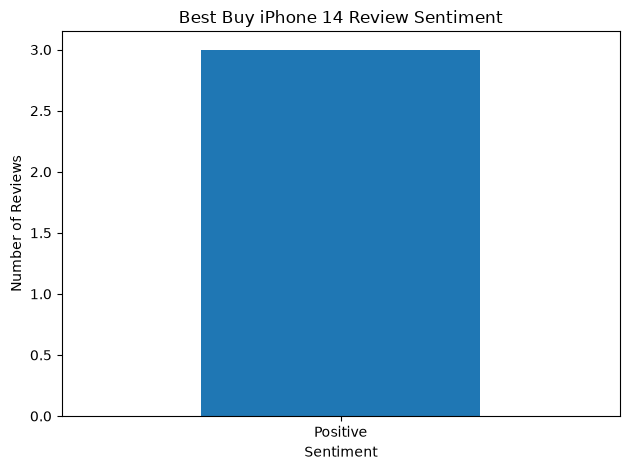

In [21]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the analyzed reviews
df = pd.read_csv("data/bestbuy_reviews_with_sentiment.csv")

# Count reviews in each sentiment category
sentiment_counts = df["sentiment"].value_counts()

print("Sentiment distribution:")
print(sentiment_counts)

# Create a bar chart
sentiment_counts.plot(kind="bar")

plt.title("Best Buy iPhone 14 Review Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [22]:

import pandas as pd

df = pd.read_csv("data/bestbuy_reviews_with_sentiment.csv")

print("BEST BUY IPHONE 14 - REVIEW SUMMARY")
print("=" * 40)

print("Total reviews analyzed:", len(df))
print("Average star rating:", round(df["rating"].mean(), 2))
print("Positive reviews:", (df["sentiment"] == "Positive").sum())
print("Neutral reviews:", (df["sentiment"] == "Neutral").sum())
print("Negative reviews:", (df["sentiment"] == "Negative").sum())

print("\nAverage rating by sentiment:")
print(df.groupby("sentiment")["rating"].mean().round(2))

print("\nReview data quality:")
print("Missing review text:", df["review_text"].isna().sum())
print("Duplicate review IDs:", df["primary_key"].duplicated().sum())


BEST BUY IPHONE 14 - REVIEW SUMMARY
Total reviews analyzed: 3
Average star rating: 4.67
Positive reviews: 3
Neutral reviews: 0
Negative reviews: 0

Average rating by sentiment:
sentiment
Positive    4.67
Name: rating, dtype: float64

Review data quality:
Missing review text: 0
Duplicate review IDs: 0


In [23]:
import pandas as pd

df = pd.read_csv("data/bestbuy_reviews.csv")

print("Total reviews:", len(df))
print("\nReview IDs:")
print(df["primary_key"].tolist())

print("\nCheck for placeholders:")
placeholder_rows = df[
    df.astype(str).apply(
        lambda col: col.str.contains(
            "PASTE ACTUAL|Enter the actual|Enter the displayed",
            case=False,
            regex=True
        )
    ).any(axis=1)
]

print("Placeholder rows:", len(placeholder_rows))
display(placeholder_rows)

Total reviews: 3

Review IDs:
['BB001', 'BB002', 'BB003']

Check for placeholders:
Placeholder rows: 0


,primary_key,title,review_text,date,rating,source,reviewer_name


In [24]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB004",
    "title": "Good for used",
    "review_text": "Took a long time to arrive, shipped after a week opposed to the supposed two days. Battery health was underwhelming at 85%, was hoping for a bit higher after reading other reviews. Other than that, good purchase",  # Replace with the actual date (YYYY-MM-DD)
    "date": "2025-07-31",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 4,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Sam"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 4


In [25]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB005",
    "title": "iphone 14",
    "review_text": "The phone has no scratches but it is at 85% battery life",
    "date": "2025-08-13",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 4,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Sammy"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 5


In [26]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB006",
    "title": "Renewed I Phone",
    "review_text": "Up on receipt I was disappointed to note that although this item was described as Excellent it was at 83% battery status. Since I was upgrading from a iPhone SE I assumed the migration would be easy. Once the SIM card was transferred my connection to my provider be came a problem. No connection or lost connection. 2 phone calls, 2 visits to a Vidéotron shop …re insert nano sim card, new SIM card..the conclusion possible defective SIM card tray or connection.Finally connected with a E SIM. 12 hours lost time, phone calls. Conclusion ..defective sim card tray or connection. Learned that my purchase was an Asian or Japanese refurbished product. Nothing in the box sent me had any info. As to who to call,WHO IS SELLER no information as to Warranty…..IF ANYBODY READS THIS WHERE IS THE INFO. ONE ONE YEAR WARRANTY STAED IN THE AD",
    "date": "2026-06-16",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 1,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Paul M"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 6


In [27]:
import pandas as pd

df = pd.read_csv("data/bestbuy_reviews.csv")

print("Total reviews:", len(df))
display(df)

Total reviews: 6


,primary_key,title,review_text,date,rating,source,reviewer_name
0,BB001,Truly Excellent and Worth the Price,I purchased a refurbished iPhone 14 in Excelle...,2025-09-18,5,Best Buy Canada,Space Marcus
1,BB002,Great phone!,Perfect phone for me for the price. Much bette...,2025-09-18,4,Best Buy Canada,Reviewed by Bunny
2,BB003,Great functionality wise and cosmetically,"received the phone extremely fast, came in gen...",2025-02-12,5,Reviewed by Mar,Reviewed by Mar
3,BB004,Good for used,"Took a long time to arrive, shipped after a we...",2025-07-31,4,Best Buy Canada,Reviewed by Sam
4,BB005,iphone 14,The phone has no scratches but it is at 85% ba...,2025-08-13,4,Best Buy Canada,Reviewed by Sammy
5,BB006,Renewed I Phone,Up on receipt I was disappointed to note that ...,2026-06-16,1,Best Buy Canada,Reviewed by Paul M


In [28]:
import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

df = pd.read_csv("data/bestbuy_reviews.csv")

analyzer = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    score = analyzer.polarity_scores(str(text))["compound"]

    if score >= 0.05:
        sentiment = "Positive"
    elif score <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    return pd.Series([sentiment, score])

df[["sentiment", "sentiment_score"]] = df["review_text"].apply(
    analyze_sentiment
)

df.to_csv("data/bestbuy_reviews_with_sentiment.csv", index=False)
df.to_excel("data/bestbuy_reviews_with_sentiment.xlsx", index=False)

print("Total reviews analyzed:", len(df))
display(df[["title", "rating", "sentiment", "sentiment_score"]])

Total reviews analyzed: 6


,title,rating,sentiment,sentiment_score
0,Truly Excellent and Worth the Price,5,Positive,0.9747
1,Great phone!,4,Positive,0.9360
2,Great functionality wise and cosmetically,5,Positive,0.9750
3,Good for used,4,Positive,0.6908
4,iphone 14,4,Negative,-0.1531
5,Renewed I Phone,1,Negative,-0.8289


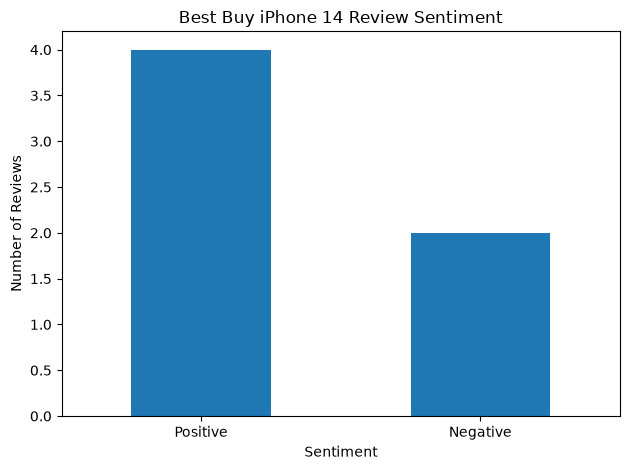

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/bestbuy_reviews_with_sentiment.csv")

sentiment_counts = df["sentiment"].value_counts()

sentiment_counts.plot(kind="bar")

plt.title("Best Buy iPhone 14 Review Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
import pandas as pd

df = pd.read_csv("data/bestbuy_reviews.csv")

print("Reviews collected:", len(df))
print("Missing values:")
print(df.isnull().sum())
print("Duplicate review IDs:", df["primary_key"].duplicated().sum())

Reviews collected: 6
Missing values:
primary_key      0
title            0
review_text      0
date             0
rating           0
source           0
reviewer_name    0
dtype: int64
Duplicate review IDs: 0


In [31]:
import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB007",
    "title": "",
    "review_text": " Took a long time to arrive, shipped after a week opposed to the supposed two days. Battery health was underwhelming at 85%, was hoping for a bit higher after reading other reviews. Other than that, good purchase. ",
    "date": "2025-07-31",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 4,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Sam"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 7


In [32]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB008",
    "title": "Iphone 14 128gb from Techachi",
    "review_text": "Communication was on point, received a responses in 1 business day. Delivery speed was reasonable got it in a week. Phone condition in terms of physicality, it only has minor scratches which isn’t visible to the naked eye. Plus the screen display is not a genuine apple product, it says “Display Not Recognized”. Battery health was a bit disappointing it’s at 84% stating that its in excellent condition and the seller telling me the requirement for best buy product is 85% and above. Above all everything else is working perfectly fine",
    "date": "2026-07-28",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 3,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Sam"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 8


In [ ]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB009",
    "title": "Like New!",
    "review_text": "This phone shipped to me in just a few days and had no scratches whatsoever. Looks like new! It's fast and everything is working well. Very happy to buy a refurbished phone that is also such nice quality. The colour is cool too! Nearly black but with the tiniest hint of blue.",
    "date": "2025-07-14",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by TB"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 9


In [34]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0010",
    "title": "Great customer service",
    "review_text": "This phone arrived in great condition but unfortunately didn’t work. I contacted the seller, and was immediately sent a label to ship it back for free. Within a day or two, I had a full refund. I was very frustrated that the phone didn’t work, but very impressed with the seamless customer service.",
    "date": "2026-03-23",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 2,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Kelly"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 10


In [35]:
import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

df = pd.read_csv("data/bestbuy_reviews.csv")

analyzer = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    score = analyzer.polarity_scores(str(text))["compound"]

    if score >= 0.05:
        sentiment = "Positive"
    elif score <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    return pd.Series([sentiment, score])

df[["sentiment", "sentiment_score"]] = df["review_text"].apply(
    analyze_sentiment
)

df.to_csv("data/bestbuy_reviews_with_sentiment.csv", index=False)
df.to_excel("data/bestbuy_reviews_with_sentiment.xlsx", index=False)

print("Total reviews analyzed:", len(df))
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Total reviews analyzed: 10

Sentiment distribution:
sentiment
Positive    8
Negative    2
Name: count, dtype: int64


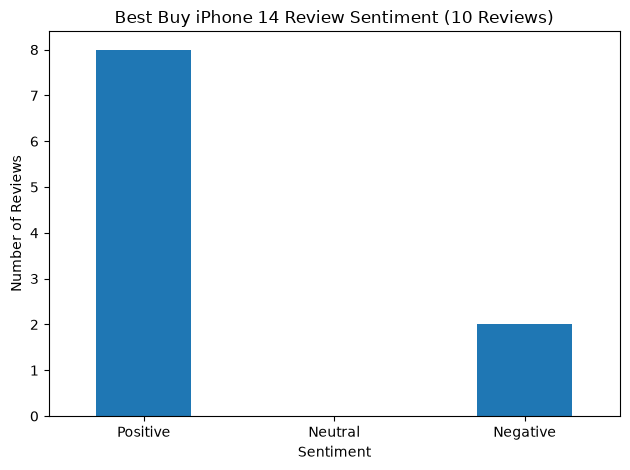

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/bestbuy_reviews_with_sentiment.csv")

counts = df["sentiment"].value_counts().reindex(
    ["Positive", "Neutral", "Negative"], fill_value=0
)

counts.plot(kind="bar")
plt.title("Best Buy iPhone 14 Review Sentiment (10 Reviews)")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [37]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0011",
    "title": "Good phone",
    "review_text": "This phone is what I expected. Was easy to get running. However, more than a few scratches on the screen and masked with a cheap screen protector which cracked within a few days. Came with one USB to Lightning cable and one plastic case. Battery capacity at 86. Arrived in a reasonable amount of time.",
    "date": "2026-04-14",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 4,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Scarlet"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 11


In [38]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0012",
    "title": "Outstanding iPhone 14",
    "review_text": "Purchased an excellent condition refurbished iPhone 14. It was received in like new condition without any issues or scuffs. Phone works as expected with 100% battery health. Would definitely buy from again.",
    "date": "2025-11-01",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Wee Irish"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 12


In [39]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0013",
    "title": "Overall good, but the refurbished rating is a lie",
    "review_text": "Was told the phone was in “Excellent” refurbished condition, the battery health is at 85%. Disappointing to say the least as I paid for something in excellent condition. Don’t recommend the seller at all.",
    "date": "2025-08-27",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 2,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Josh"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 13


In [40]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0014",
    "title": "Better Cleaning Needed",
    "review_text": "The phone was in good condition but very dirty (all the crevices and lines have something in it. I wished it was cleaned better prior to being shipped and sent to me.",
    "date": "2025-10-18",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 4,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Sisi"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 14


In [41]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0015",
    "title": "Refurbished Excellent = 87% Battery Health",
    "review_text": "I realize that the iPhone is refurbished, but I didn't expect a \"Refurbished (Excellent)\" phone to have only 87% Battery Health. A bit of a let down to be honest.",
    "date": "2026-10-09",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 3,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Chris"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 15


In [42]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0016",
    "title": "All good!",
    "review_text": "We purchased an iPhone 14 in excellent condition and it certainly is. It works great, looks great and it arrived ahead of what they anticipated for delivery!",
    "date": "2026-01-14",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by SRK"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 16


In [43]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0017",
    "title": "As advertised",
    "review_text": "The phone was in good condition, no serious damage. The battery life was about 86%. The price was comparable or cheaper than anything I could find in person.",
    "date": "2026-05-11",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Rover"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 17


In [44]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0018",
    "title": "Ok",
    "review_text": "Overall decent value, however, was disappointed that for a ‘refurbished excellent’ the battery health capacity was only 83%. Live and learn I guess…",
    "date": "2026-01-09",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 3,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Value Buyer"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 18


In [45]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0019",
    "title": "not excellent",
    "review_text": "Came with a few scratches nothing crazy but then the touchscreen became unresponsive within 2 days of purchase. wouldn't really recommend",
    "date": "2026-01-12",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 2,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": " Reviewed by kidemay"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 19


In [46]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0020",
    "title": "Great replacement phone.",
    "review_text": "I purchased this phone as an upgrade from my previous phone. It arrived within a week of placing my order in excellent condition.",
    "date": "2026-05-21",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Cahty"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 20


In [47]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0021",
    "title": "Great!",
    "review_text": "The phone came quickly and works well - there was also a case which we weren’t expecting so it was a nice surprise ! Thank you !",
    "date": "2026-03-03",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Becs"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 21


In [48]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0022",
    "title": "First time purchasing from BB",
    "review_text": "Needed a newer phone, description said (excellent) Was expecting a better battery health than 91% Otherwise, have no complaints",
    "date": "2026-07-16",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 3,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Shawn "
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 22


In [49]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0023",
    "title": "Incredibly slow processing and shipping",
    "review_text": "I ordered on May 8th, it is now June 1st and I still have not yet recieved the phone I ordered. This feels unacceptable.",
    "date": "2026-06-01",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 1,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by VS"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 23


In [50]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0024",
    "title": "iphone 14 128GB",
    "review_text": "so far the phone is very smart with no sign of wire although the battery health is 85% the battery still last long.",
    "date": "2025-11-18",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by PEACE"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 24


In [51]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0025",
    "title": "I recommend seller",
    "review_text": "Fast delivery time and nice packaging. Item matched description. Phone has been working fine for the past 3 months.",
    "date": "2026-01-30",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Mark Regal"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 25


In [52]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0026",
    "title": "Terrible",
    "review_text": "Techachi 3rd party purchase. Phone didn't work. Looked like not refurbished. After market parts not Apple",
    "date": "2026-08-25",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 1,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by jenn"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 26


In [53]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0027",
    "title": "Satisfied",
    "review_text": "Best price I could find. Came within a week. Great condition and works well.",
    "date": "2026-10-17",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by GG"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 27


In [54]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0028",
    "title": "I PHONE 14 REFURBISH",
    "review_text": "Arrive quick, everything works as intended, looks like the day it came out of the box.",
    "date": "2026-05-07",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Guy"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 28


In [55]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0029",
    "title": "Very happy with my purchase",
    "review_text": "Purchased a refurbished iphone 14 in excellent condition and am very pleased with it!",
    "date": "2025-11-12",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Hank"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 29


In [56]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0030",
    "title": "Good product, good price",
    "review_text": "Bought this phone for my son. He is very happy with it, especially the camera.",
    "date": "2026-03-04",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Jo"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 30


In [57]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0031",
    "title": "Do not buy refurbished/renewed",
    "review_text": "Do not buy refurbished/renewed. They are all second hand, used phones.",
    "date": "2026-08-03",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 1,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Ben Daee "
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 31


In [58]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0032",
    "title": "That's weird",
    "review_text": "Very slow service and shipping 2 different details about same iPhone",
    "date": "2026-01-18",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 1,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Nowai"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 32


In [59]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0033",
    "title": "Phone works excellent",
    "review_text": "Phone works excellent no problems whatsoever in perfect condition",
    "date": "2026-05-06",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Derek"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 33


In [60]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0034",
    "title": "No cord",
    "review_text": "No cord came with the phone. False advertisement. Maybe fraud.",
    "date": "2026-04-20",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 1,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Null"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 34


In [61]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0035",
    "title": "Good thank you",
    "review_text": "Arrived in good time and is in great condition as advertised.",
    "date": "2026-08-04",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Rod"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 35


In [62]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0036",
    "title": "Excellent phone, 100% battery life, just like new.",
    "review_text": "My son loves his birthday gift! It is so new with 100% battery life! Thank you seller.",
    "date": "2025-10-211",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by JCBrus"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 36


In [63]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0037",
    "title": "I recommend seller",
    "review_text": "Fast delivery time and nice packaging. Item matched description. Phone has been working fine for the past 3 months.",
    "date": "2026-01-30",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 5,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Mark Regal"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 37


In [64]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0038",
    "title": "First time purchasing from BB",
    "review_text": "Needed a newer phone, description said (excellent) Was expecting a better battery health than 91% Otherwise, have no complaints",
    "date": "2026-07-16",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 3,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Shawn "
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 38


In [65]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0039",
    "title": "Overheating",
    "review_text": "But this phone from my husband it’s not taking charge. It’s overheating not sure why, but we are having so much issue with it. And I’m not sure what to do",
    "date": "2026-08-08",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 1,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by TT "
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 39


In [66]:

import pandas as pd

file_path = "data/bestbuy_reviews.csv"
df = pd.read_csv(file_path)

new_review = {
    "primary_key": "BB0040",
    "title": "Refurbished Excellent = 87% Battery Health",
    "review_text": "I realize that the iPhone is refurbished, but I didn't expect a \"Refurbished (Excellent)\" phone to have only 87% Battery Health. A bit of a let down to be honest.",
  "date": "2026-10-09",  # Replace with the actual date (YYYY-MM-DD)
    "rating": 3,           # Replace with the actual star rating
    "source": "Best Buy Canada",
    "reviewer_name": "Reviewed by Chris"
}

if new_review["primary_key"] not in df["primary_key"].astype(str).values:
    df = pd.concat([df, pd.DataFrame([new_review])], ignore_index=True)
    df.to_csv(file_path, index=False)

print("Total reviews saved:", len(df))


Total reviews saved: 40


In [67]:
import pandas as pd

df = pd.read_csv("data/bestbuy_reviews.csv")
print("Total reviews collected:", len(df))

Total reviews collected: 40
